# Final Assignment
## 230X - High Frequency Finance

Daisy Niu

Hrafnhildur Jonsdottir

Paraj Goyal

Reza Zamani

Saurabh Baranwal

### a) Choose 2 equities and one FX pair

We continue with **NVDA** and **QRVO**, which we used in HW1 and HW2. They fit the assignment well because NVDA is highly liquid and QRVO is considerably less liquid. For the FX pair we use **EUR/USD**, the most actively traded currency pair.

### b) Choose a one-month period

We use **March 2025**, since we have complete data for all three securities in that month.

### c) Choose 2 trading signals from the paper plus our own signal

From the paper we use **Moving Average (MA)** and **Support and Resistance (SR)**. We chose SR over Channel Breakout (CB) because CB only trades when a channel exists, so SR generates more trades.

Our own signal is **mean reversion on a z-score**. Both paper signals are trend following, so this one takes the opposite side:

$$
z_t = \frac{m_t - \text{ma}_t(l, m)}{\text{std}_t(l, m)}
$$

where $m_t$ is the midpoint and $l$ is the lookback in intervals.

- **Short** if $z_t > k$
- **Long** if $z_t < -k$
- **Close** the position when $z_t$ crosses 0

In [ ]:
import databento as db
import pandas as pd
from pathlib import Path

client = db.Historical("Your-API")
TZ = "America/New_York"
RAW = Path("data/raw"); RAW.mkdir(parents=True, exist_ok=True)

days = pd.bdate_range("2025-03-03", "2025-03-31")  # 21 trading days, no US holidays

SOURCES = {
    "equities": dict(dataset="XNAS.ITCH", symbols=["NVDA", "QRVO"], stype_in="raw_symbol"),
    "fx":       dict(dataset="GLBX.MDP3", symbols=["6E.v.0"],       stype_in="continuous"),
}

def window(day):
    lo = pd.Timestamp(f"{day.date()} 09:30", tz=TZ).tz_convert("UTC")
    hi = pd.Timestamp(f"{day.date()} 16:00", tz=TZ).tz_convert("UTC")
    return lo.isoformat(), hi.isoformat()

for name, src in SOURCES.items():
    cost = 0.0
    for d in days:
        lo, hi = window(d)
        cost += client.metadata.get_cost(schema="mbp-1", start=lo, end=hi, **src)
    print(name, "estimated cost: $", round(cost, 2))

equities estimated cost: $ 0.0
fx estimated cost: $ 0.0


***Download, one file per day***


In [ ]:
KEEP = ["symbol", "action", "side", "price", "size",
        "bid_px_00", "ask_px_00", "bid_sz_00", "ask_sz_00", "flags", "sequence"]

for name, src in SOURCES.items():
    for d in days:
        f = RAW / f"{name}_mbp1_{d.date()}.parquet"
        if f.exists():
            continue
        lo, hi = window(d)
        data = client.timeseries.get_range(schema="mbp-1", start=lo, end=hi, **src)
        df = data.to_df(price_type="float")[KEEP]
        if name == "fx":
            df["symbol"] = "EURUSD"
        df.index = df.index.tz_convert(TZ); df.index.name = "ts"
        df.to_parquet(f)
        print(name, d.date(), df.shape)

***Clean quotes and trades per symbol***

In [ ]:
CLEAN = Path("data/clean"); CLEAN.mkdir(parents=True, exist_ok=True)

for sym, name in [("NVDA", "equities"), ("QRVO", "equities"), ("EURUSD", "fx")]:
    q_parts, t_parts = [], []
    for d in days:
        df = pd.read_parquet(RAW / f"{name}_mbp1_{d.date()}.parquet")
        df = df[df["symbol"] == sym]

        bbo = df[["bid_px_00", "ask_px_00", "bid_sz_00", "ask_sz_00"]].copy()
        bbo.columns = ["bid", "ask", "bid_sz", "ask_sz"]
        bbo = bbo[bbo["ask"] > bbo["bid"]]
        bbo = bbo[bbo.ne(bbo.shift()).any(axis=1)]   # keep only rows where the touch changed
        bbo["mid"] = (bbo["bid"] + bbo["ask"]) / 2
        q_parts.append(bbo)

        t_parts.append(df.loc[df["action"] == "T", ["price", "size", "side"]])

    quotes, trades = pd.concat(q_parts), pd.concat(t_parts)
    quotes.to_parquet(CLEAN / f"quotes_{sym}_2025-03.parquet")
    trades.to_parquet(CLEAN / f"trades_{sym}_2025-03.parquet")
    print(sym, "| quote updates", len(quotes), "| trades", len(trades),
          "| median spread", round((quotes["ask"] - quotes["bid"]).median(), 5))

NVDA | quote updates 103115808 | trades 9537782 | median spread 0.01
QRVO | quote updates 755237 | trades 211859 | median spread 0.05
EURUSD | quote updates 13097861 | trades 525445 | median spread 5e-05


***Start here if you already have the clean data***

If `data/clean/` already holds the cleaned files, skip the download and cleaning cells above. Click into the cell below and run it and every cell after it. That produces tick frequency, OFI, MA, SR, the P&L reports and Figure 6.

**Memory.** NVDA has about 100M quotes for the month. From here on, the cells we wrote read **one trading day at a time** through `load_day`. No position is held overnight, so results are identical to loading the whole month, and peak memory is about one NVDA day.

The cell checks that every file is in `data/clean/`. The quotes files are required. The trades files are only used for the trades-per-day count in the tick-frequency table.

In [ ]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path

TZ = "America/New_York"
SYMBOLS = ["NVDA", "QRVO", "EURUSD"]
DAYS = pd.bdate_range("2025-03-03", "2025-03-31")   # 21 trading days, no US holidays

CLEAN = Path("data/clean")   # the cleaned files, next to this notebook

for kind in ["quotes", "trades"]:
    for sym in SYMBOLS:
        f = CLEAN / f"{kind}_{sym}_2025-03.parquet"
        print(f"{'ok     ' if f.exists() else 'MISSING'}  {f.name}")

def load_day(kind, sym, day, columns=None):
    """One trading day of quotes or trades, read straight from the monthly file.

    Only that day's rows are loaded, so NVDA (~100M quotes for the month) never
    has to fit in memory at once. Every cell below works one day at a time.
    """
    path = CLEAN / f"{kind}_{sym}_2025-03.parquet"
    idx = pq.read_schema(path).pandas_metadata["index_columns"][0]
    lo = pd.Timestamp(day.date(), tz=TZ)
    t = pq.read_table(path, columns=columns, use_pandas_metadata=True,
                      filters=[(idx, ">=", lo), (idx, "<", lo + pd.Timedelta("1D"))])
    return t.to_pandas()


***Tick frequency per asset***

How often the book changes sets how much can happen during an execution delay. *Mid changes per 100 ms* is the expected number of price moves a 100 ms delay misses. Saved to `tick_frequency.csv`.

In [3]:
SESSION_S = 6.5 * 3600  # 09:30-16:00

rows = []
for sym in SYMBOLS:
    n_quotes = n_days = mid_moves = 0
    gaps, spread_bps, spread_counts = [], [], pd.Series(dtype=float)
    for day in DAYS:
        q = load_day("quotes", sym, day, ["bid", "ask", "mid"])
        if q.empty:
            continue
        n_days += 1
        n_quotes += len(q)
        gaps.append((np.diff(q.index.asi8) / 1e6).astype(np.float32))   # ms between updates, same day only
        mid_moves += int((np.diff(q["mid"].to_numpy()) != 0).sum())
        spread = (q["ask"] - q["bid"]).to_numpy()
        spread_counts = spread_counts.add(pd.Series(spread).round(10).value_counts(), fill_value=0)
        spread_bps.append((spread / q["mid"].to_numpy() * 1e4).astype(np.float32))
        del q
    gaps, spread_bps = np.concatenate(gaps), np.concatenate(spread_bps)
    sc = spread_counts.sort_index()
    median_spread = sc.index[np.searchsorted(sc.cumsum().to_numpy(), sc.sum() / 2)]
    n_trades = pq.ParquetFile(CLEAN / f"trades_{sym}_2025-03.parquet").metadata.num_rows
    rows.append({
        "symbol": sym,
        "quote updates / day": n_quotes / n_days,
        "quote updates / s": n_quotes / n_days / SESSION_S,
        "mid changes / s": mid_moves / n_days / SESSION_S,
        "mid changes per 100 ms": mid_moves / n_days / SESSION_S * 0.1,
        "trades / day": n_trades / n_days,
        "median ms between updates": np.median(gaps),
        "% updates < 100 ms apart": (gaps < 100).mean() * 100,
        "median spread ($)": median_spread,
        "median spread (bps)": np.median(spread_bps),
    })
    del gaps, spread_bps

tick = pd.DataFrame(rows).set_index("symbol")
tick.to_csv("tick_frequency.csv")
fmt = lambda x: f"{x:,.0f}" if abs(x) >= 100 else f"{x:,.2f}" if abs(x) >= 1 else f"{x:.3g}"
print(tick.T.to_string(float_format=fmt))


symbol                         NVDA   QRVO  EURUSD
quote updates / day       4,910,277 35,964 623,708
quote updates / s               210   1.54   26.65
mid changes / s               22.56  0.514    1.61
mid changes per 100 ms         2.26 0.0514   0.161
trades / day                454,180 10,089  25,021
median ms between updates    0.0527   0.36    0.12
% updates < 100 ms apart      99.19  75.70   93.28
median spread ($)              0.01   0.05   5e-05
median spread (bps)           0.905   7.11   0.461


# Implement the strategy

In [4]:
WINDOW = pd.Timedelta("2s")
DELAYS = {"0ms": pd.Timedelta(0), "100ms": pd.Timedelta("100ms"), "1s": pd.Timedelta("1s")}
CALIB_END = "2025-03-07" # first week sets depth and k, then both stay fixed
Q = 0.95 # "strong" = top 5% of |OFI| in the first week

def day_ofi(d):
    """Rolling 2s order flow imbalance for one day, exact in event time."""
    pb, pa = d["bid"].to_numpy(), d["ask"].to_numpy()
    sb, sa = d["bid_sz"].to_numpy(float), d["ask_sz"].to_numpy(float)
    # buyers gain: bid up (+new size), same bid (+size change), bid down (-old size)
    e_bid = np.where(pb[1:] > pb[:-1], sb[1:], np.where(pb[1:] == pb[:-1], sb[1:] - sb[:-1], -sb[:-1]))
    # sellers gain: ask down (+new size), same ask (+size change), ask up (-old size)
    e_ask = np.where(pa[1:] < pa[:-1], sa[1:], np.where(pa[1:] == pa[:-1], sa[1:] - sa[:-1], -sa[:-1]))
    e, t = e_bid - e_ask, d.index[1:]
    # each update adds its pressure at t and removes it again at t + 2s
    ev = pd.concat([pd.Series(e, index=t), pd.Series(-e, index=t + WINDOW)])
    return ev.groupby(level=0).sum().sort_index().cumsum()

def positions(x, k):
    """+1 after x > k until x <= 0, -1 after x < -k until x >= 0, else flat."""
    lng = pd.Series(np.where(x > k, 1.0, np.where(x <= 0, 0.0, np.nan)), index=x.index).ffill().fillna(0.0)
    sht = pd.Series(np.where(x < -k, 1.0, np.where(x >= 0, 0.0, np.nan)), index=x.index).ffill().fillna(0.0)
    pos = lng - sht
    pos.iloc[-1] = 0.0 # always flat at the end of the day
    return pos

def run_day(d, pos, delay):
    dpos = pos.diff().fillna(pos.iloc[0])
    tr = dpos[dpos != 0]
    orders = pd.DataFrame({"ts": tr.index + delay, "qty": tr.to_numpy()})
    quotes = d[["bid", "ask", "mid"]].rename_axis("ts").reset_index()
    f = pd.merge_asof(orders, quotes, on="ts", direction="backward")
    px = np.where(f["qty"] > 0, f["ask"], f["bid"])
    ref = d["mid"].mean()
    return {"ret_bps": -(f["qty"] * px).sum() / ref * 1e4,
            "ret_mid_bps": -(f["qty"] * f["mid"]).sum() / ref * 1e4,
            "trades": len(f)}

OFI_COLS = ["bid", "ask", "mid", "bid_sz", "ask_sz"]

def ofi_calibration(sym):
    """Typical depth and threshold k from the first week, one day at a time."""
    calib = [day for day in DAYS if str(day.date()) <= CALIB_END]
    depths, ofis = [], []
    for day in calib:
        d = load_day("quotes", sym, day, OFI_COLS)
        depths.append(((d["bid_sz"] + d["ask_sz"]) / 2).mean())
        ofis.append(day_ofi(d).to_numpy())   # values only, to keep memory low
        del d
    depth = np.mean(depths)
    k = np.quantile(np.abs(np.concatenate(ofis) / depth), Q)
    return depth, k

rows = []
for sym in SYMBOLS:
    depth, k = ofi_calibration(sym)
    print(sym, "| typical depth", round(depth, 1), "| k", round(k, 3))
    for day in DAYS:
        if str(day.date()) <= CALIB_END:
            continue
        d = load_day("quotes", sym, day, OFI_COLS)
        pos = positions(day_ofi(d) / depth, k)
        for name, delay in DELAYS.items():
            rows.append({"symbol": sym, "day": day.date(), "delay": name, **run_day(d, pos, delay)})
        del d

res = pd.DataFrame(rows)
res.to_csv("ofi_delay_results.csv", index=False)

summary = res.groupby(["symbol", "delay"])[["ret_bps", "ret_mid_bps", "trades"]].mean().unstack("delay")
summary = summary.reindex(columns=list(DELAYS), level=1).reindex(SYMBOLS)
print(summary.round(2))

for col in ["ret_bps", "ret_mid_bps"]:
    s = summary[col]
    print("\ncost of delay,", col, "(bps per day)")
    print(pd.DataFrame({"100ms": s["0ms"] - s["100ms"], "1s": s["0ms"] - s["1s"]}).round(2))

NVDA | typical depth 722.6 | k 18.641
QRVO | typical depth 163.5 | k 9.798
EURUSD | typical depth 20.5 | k 9.491
       ret_bps                 ret_mid_bps                 trades           \
delay      0ms   100ms      1s         0ms  100ms     1s      0ms    100ms   
symbol                                                                       
NVDA   -609.21 -924.53 -948.50      351.75 -40.84 -59.71  1530.88  1530.88   
QRVO   -451.44 -517.78 -554.97      110.49  57.74  29.02   160.25   160.25   
EURUSD -181.09 -191.76 -188.31        7.14  -1.52   2.48   633.94   633.94   

                 
delay        1s  
symbol           
NVDA    1530.88  
QRVO     160.25  
EURUSD   633.94  

cost of delay, ret_bps (bps per day)
         100ms      1s
symbol                
NVDA    315.32  339.29
QRVO     66.34  103.53
EURUSD   10.68    7.22

cost of delay, ret_mid_bps (bps per day)
         100ms      1s
symbol                
NVDA    392.59  411.46
QRVO     52.75   81.47
EURUSD    8.65    4.66


Before the spread: average daily return, filled at the mid


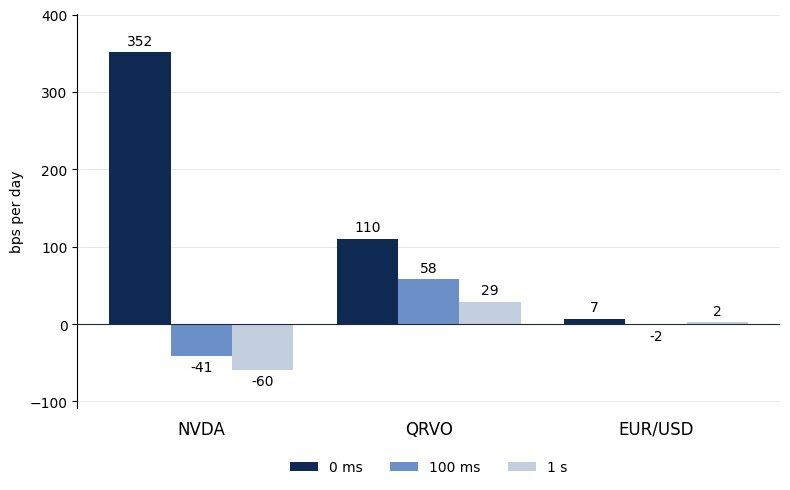

After the spread: average daily return, buy at ask and sell at bid


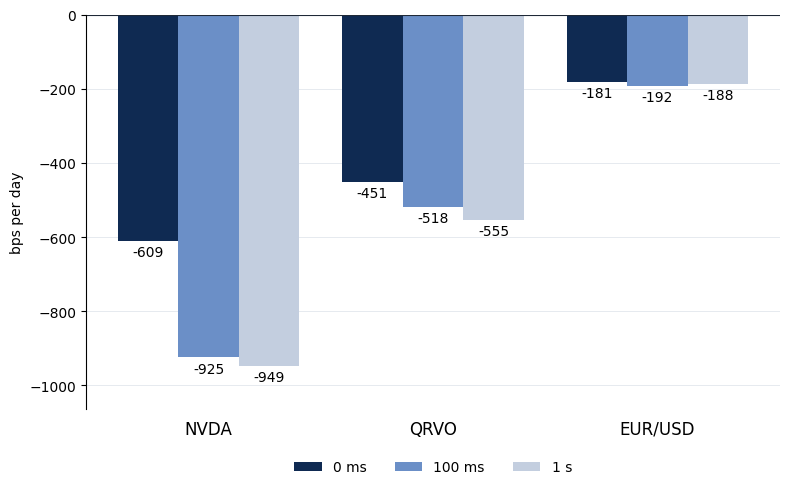

        100 ms    1 s
symbol               
NVDA     315.0  339.0
QRVO      66.0  104.0
EURUSD    11.0    7.0


In [5]:
import matplotlib.pyplot as plt

res = pd.read_csv("ofi_delay_results.csv")
SYMBOLS = ["NVDA", "QRVO", "EURUSD"]
DELAYS = ["0ms", "100ms", "1s"]
LABELS = {"0ms": "0 ms", "100ms": "100 ms", "1s": "1 s"}
COLORS = {"0ms": "#0F2A52", "100ms": "#6B8FC7", "1s": "#C3CEDF"}

def delay_chart(col, title, fname):
    avg = res.groupby(["symbol", "delay"])[col].mean().unstack("delay").loc[SYMBOLS, DELAYS]
    fig, ax = plt.subplots(figsize=(8, 5))
    width = 0.27
    print(title)
    for i, dly in enumerate(DELAYS):
        x = [j + (i - 1) * width for j in range(len(SYMBOLS))]
        bars = ax.bar(x, avg[dly], width, label=LABELS[dly], color=COLORS[dly])
        ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=10)
    ax.axhline(0, color="#1F2937", linewidth=0.8)
    ax.set_xticks(range(len(SYMBOLS)))
    ax.set_xticklabels(["NVDA", "QRVO", "EUR/USD"], fontsize=12)
    ax.tick_params(axis="x", length=0, pad=8)
    ax.set_ylabel("bps per day")
    ax.grid(axis="y", color="#E2E6EC", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.margins(y=0.12)
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    fig.tight_layout()
    fig.savefig(fname, dpi=200)
    plt.show()
    return avg

before = delay_chart("ret_mid_bps", "Before the spread: average daily return, filled at the mid",
                     "delay_before_spread.png")

after = delay_chart("ret_bps", "After the spread: average daily return, buy at ask and sell at bid",
                    "delay_after_spread.png")

cost = pd.DataFrame({"100 ms": after["0ms"] - after["100ms"], "1 s": after["0ms"] - after["1s"]})
print(cost.round(0))

# Backtest engine

`backtest(quotes, pos, delay)` takes any signal as a target position in {-1, 0, +1} indexed by the time the signal fires, and fills each change at the quote in effect at signal time + delay. Buys pay the ask and sells receive the bid (`fill="touch"`), or both fill at the mid (`fill="mid"`) to show returns before the spread. The whole $1,000,000 book goes into every entry, so returns compound, and the position is closed at the last quote of each day.

EUR/USD is the CME 6E future (125,000 EUR per contract); positions are sized in fractional contracts, so returns do not depend on the multiplier.

**To add a signal:** build `pos` for each symbol, call `backtest` for each delay and fill, and append rows to `results` with your signal name.

In [6]:
CAPITAL = 1_000_000
TZ = "America/New_York"

def backtest(quotes, pos, delay, capital=CAPITAL, fill="touch", mult=1.0):
    """Run any signal through delayed execution on a $1M book.

    quotes: clean quotes for the month (bid, ask, mid), indexed by ts
    pos:    target position in {-1, 0, +1}, indexed by the time the signal fires
    delay:  pd.Timedelta, each order fills at the quote in effect at signal time + delay
    fill:   "touch" buys at the ask and sells at the bid, "mid" fills at the mid
    mult:   contract multiplier (125,000 EUR for 6E futures, 1 for shares)

    The whole book goes into every entry (so returns compound), and the
    strategy is closed at the last quote of each day.
    Returns (summary dict, round trips, end-of-day book value).
    """
    # orders = every change in target position, plus a forced close at each day's last quote
    orders = []
    for day, p in pos.astype(float).groupby(pos.index.date):
        close = pd.Timestamp(f"{day} 16:00", tz=TZ)
        last_quote = quotes.index[quotes.index.searchsorted(close, side="right") - 1]
        p = pd.concat([p, pd.Series([0.0], index=[max(last_quote, p.index[-1])])])
        p = p[~p.index.duplicated(keep="last")]
        orders.append(p[p.ne(p.shift(fill_value=0.0))])
    orders = pd.concat(orders)

    fill_ts = orders.index + delay
    i = quotes.index.searchsorted(fill_ts, side="right") - 1   # last quote at or before fill time
    bid, ask, mid = (quotes[c].to_numpy()[i] for c in ("bid", "ask", "mid"))
    buy_px, sell_px = (mid, mid) if fill == "mid" else (ask, bid)

    cash, units, held, trips = float(capital), 0.0, 0, []
    for j, target in enumerate(orders.to_numpy()):
        if held != 0:   # close the open position
            px = sell_px[j] if held > 0 else buy_px[j]
            cash += units * px * mult
            trips.append((entry_ts, fill_ts[j], held, entry_px, px, units * (px - entry_px) * mult))
            units, held = 0.0, 0
        if target != 0:   # open a new one with the whole book
            px = buy_px[j] if target > 0 else sell_px[j]
            units = target * cash / (px * mult)
            cash -= units * px * mult
            held, entry_ts, entry_px = int(target), fill_ts[j], px

    trips = pd.DataFrame(trips, columns=["entry_ts", "exit_ts", "side", "entry_px", "exit_px", "pnl"])
    daily = trips.groupby(trips["exit_ts"].dt.date)["pnl"].sum()
    value = capital + daily.cumsum()
    final = value.iloc[-1] if len(value) else capital
    summary = {
        "final_value": final,
        "total_ret_pct": (final / capital - 1) * 100,
        "round_trips": len(trips),
        "hit_rate_pct": (trips["pnl"] > 0).mean() * 100,
        "avg_hold_s": (trips["exit_ts"] - trips["entry_ts"]).dt.total_seconds().mean(),
        "days": len(value),
    }
    return summary, trips, value

***Shared result files and the day-by-day runner***

`run_by_day(signal, sym, pos_for_day)` runs a signal through `backtest` for every delay and fill, one trading day at a time. Each day starts from the previous day's closing book, so returns compound exactly as in a single whole-month run.

Every signal cell saves through `save_run(signal, rows, values)`. It replaces only that signal's rows in `backtest_results.csv` (one summary row per signal/asset/delay/fill) and `daily_values.csv` (end-of-day book value). MA, SR and OFI can therefore run in any order and in separate sessions. The final P&L reports and Figure 6 are built from these two files only.

In [7]:
from pathlib import Path

# shared settings (same values as the OFI cells, repeated so each signal cell can run on its own)
CALIB_END = "2025-03-07"   # Mar 3-7 calibrates every signal, Mar 10-31 (16 days) is the test period
DELAY = {"0ms": pd.Timedelta(0), "100ms": pd.Timedelta("100ms"), "1s": pd.Timedelta("1s")}
FILLS = ["touch", "mid"]
MULT = {"NVDA": 1, "QRVO": 1, "EURUSD": 125_000}
SIGNALS = ["MA", "SR", "OFI"]
TEST_DAYS = [day for day in DAYS if str(day.date()) > CALIB_END]
values = globals().get("values", {})   # end-of-day book values, filled by each signal cell

RES_FILE, VAL_FILE = Path("backtest_results.csv"), Path("daily_values.csv")

def run_by_day(signal, sym, pos_for_day, days=TEST_DAYS, columns=("bid", "ask", "mid")):
    """Backtest one signal on one asset for every delay and fill, loading one day at a time.

    pos_for_day(quotes_of_the_day) returns that day's target positions in {-1, 0, +1}.
    Each day starts from the previous day's closing book, so returns compound exactly
    as when the whole month is passed to `backtest` at once (positions are flat overnight).
    Returns the summary rows and fills values[signal, sym, delay, fill].
    """
    book = {(dn, f): float(CAPITAL) for dn in DELAY for f in FILLS}
    trips = {key: [] for key in book}
    eod = {key: {} for key in book}
    for day in days:
        q = load_day("quotes", sym, day, list(columns))
        if q.empty:
            continue
        pos = pos_for_day(q)
        if len(pos) and (pos != 0).any():
            for (dn, f) in book:
                _, tr, v = backtest(q, pos, DELAY[dn], capital=book[dn, f], fill=f, mult=MULT[sym])
                if len(v):
                    book[dn, f] = v.iloc[-1]
                    eod[dn, f][v.index[-1]] = v.iloc[-1]
                trips[dn, f].append(tr)
        del q
    rows = []
    for (dn, f), parts in trips.items():
        tr = pd.concat(parts) if parts else pd.DataFrame(columns=["entry_ts", "exit_ts", "pnl"])
        final = book[dn, f]
        hold = (pd.to_datetime(tr["exit_ts"]) - pd.to_datetime(tr["entry_ts"])).dt.total_seconds()
        rows.append({"signal": signal, "symbol": sym, "delay": dn, "fill": f,
                     "final_value": final,
                     "total_ret_pct": (final / CAPITAL - 1) * 100,
                     "round_trips": len(tr),
                     "hit_rate_pct": (tr["pnl"] > 0).mean() * 100 if len(tr) else np.nan,
                     "avg_hold_s": hold.mean() if len(tr) else np.nan,
                     "days": len(eod[dn, f])})
        values[signal, sym, dn, f] = pd.Series(eod[dn, f], dtype=float)
    return rows

def save_run(signal, rows, values):
    """Merge one signal's results into the shared result files, replacing older rows for that signal.

    rows:   list of dicts (signal, symbol, delay, fill, + backtest summary)
    values: {(signal, symbol, delay, fill): end-of-day book value Series}
    """
    new_res = pd.DataFrame(rows)
    new_val = pd.concat([v.rename("value").rename_axis("day").reset_index()
                           .assign(signal=s, symbol=sym, delay=dl, fill=f)
                         for (s, sym, dl, f), v in values.items() if s == signal])
    for new, f in [(new_res, RES_FILE), (new_val, VAL_FILE)]:
        old = pd.read_csv(f) if f.exists() else pd.DataFrame(columns=new.columns)
        old = old[old["signal"] != signal]
        pd.concat([old, new], ignore_index=True).to_csv(f, index=False)
    print(f"saved {signal}: {len(new_res)} runs -> {RES_FILE}, {VAL_FILE}")


***OFI through the engine***

Same OFI positions as above (threshold calibrated on Mar 3-7, results on the remaining 16 days). Cost of delay (Figure 6 in the paper) is the drop in total return relative to 0 ms, in percentage points. NVDA takes about 6 minutes and 9 GB of memory.

In [8]:
results = []
for sym in SYMBOLS:
    depth, k = ofi_calibration(sym)   # same first-week depth and k as above
    results += run_by_day("OFI", sym, lambda d: positions(day_ofi(d) / depth, k),
                          columns=("bid", "ask", "mid", "bid_sz", "ask_sz"))

results = pd.DataFrame(results)
save_run("OFI", results.to_dict("records"), values)   # merges into backtest_results.csv / daily_values.csv
print(results.round(2).to_string(index=False))

# cost of delay (Figure 6): drop in total return vs. 0 ms, in percentage points
ret = results.pivot_table(index=["signal", "symbol", "fill"], columns="delay", values="total_ret_pct")
cost_of_delay = pd.DataFrame({"100ms": ret["0ms"] - ret["100ms"], "1s": ret["0ms"] - ret["1s"]})
print("\ncost of delay (percentage points of total return)")
print(cost_of_delay.round(2))


saved OFI: 18 runs -> backtest_results.csv, daily_values.csv
signal symbol delay  fill  final_value  total_ret_pct  round_trips  hit_rate_pct  avg_hold_s  days
   OFI   NVDA   0ms touch    377255.47         -62.27        12283         27.09        2.38    16
   OFI   NVDA   0ms   mid   1754560.97          75.46        12283         44.64        2.38    16
   OFI   NVDA 100ms touch    227745.02         -77.23        12283         22.20        2.38    16
   OFI   NVDA 100ms   mid    936135.96          -6.39        12283         36.56        2.38    16
   OFI   NVDA    1s touch    219188.77         -78.08        12283         23.13        2.38    16
   OFI   NVDA    1s   mid    908418.32          -9.16        12283         39.82        2.38    16
   OFI   QRVO   0ms touch    486063.35         -51.39         1288          7.92        2.33    16
   OFI   QRVO   0ms   mid   1193717.25          19.37         1288         50.08        2.33    16
   OFI   QRVO 100ms touch    437013.01         -

## Order Flow Imbalance

In [7]:
res = pd.read_csv("ofi_delay_results.csv", parse_dates=["day"])

# realized volatility per day from 1-minute midpoint returns
rows = []
for sym in SYMBOLS:
    mid = pd.read_parquet(CLEAN / f"quotes_{sym}_2025-03.parquet", columns=["mid"])["mid"]
    for day, x in mid.groupby(mid.index.date):
        r = np.log(x.resample("1min").last().dropna()).diff().dropna()
        rows.append({"symbol": sym, "day": pd.Timestamp(day), "rv_bps": np.sqrt((r ** 2).sum()) * 1e4})
rv = pd.DataFrame(rows)

wide = res.pivot_table(index=["symbol", "day"], columns="delay", values="ret_mid_bps").reset_index()
wide["cost_100ms"] = wide["0ms"] - wide["100ms"]
wide["cost_1s"] = wide["0ms"] - wide["1s"]
wide = wide.merge(rv, on=["symbol", "day"])
wide["regime"] = np.where(wide["rv_bps"] > wide.groupby("symbol")["rv_bps"].transform("median"),
                          "high vol", "low vol")

print(wide.groupby(["symbol", "regime"])[["rv_bps", "0ms", "cost_100ms", "cost_1s"]].mean().round(1))

                 rv_bps    0ms  cost_100ms  cost_1s
symbol regime                                      
EURUSD high vol    31.7    9.6         9.7      7.7
       low vol     25.5    4.7         7.6      1.6
NVDA   high vol   318.1  394.0       484.0    505.8
       low vol    197.6  309.5       301.1    317.2
QRVO   high vol   228.1  157.9        69.4    109.3
       low vol    172.0   63.1        36.1     53.6


# Moving Average (MA) signal

**Definition.** As in Scholtus and van Dijk (2012), eq. (3), with $m_t$ the midpoint and $ma_t(n, m) = \frac{1}{n}\sum_{j=t-n+1}^{t} m_j$ the average of the last $n$ interval midpoints:

$$
MA_t = \begin{cases} +1 & \text{if } ma_t(s, m) > (1+b)\, ma_t(l, m) \\ -1 & \text{if } ma_t(s, m) < (1-b)\, ma_t(l, m) \\ 0 & \text{otherwise} \end{cases}
$$

The target position equals $MA_t$. A position is closed when the signal changes and reversed when it flips sign.

**Intervals.** The paper's baseline interval is 60 seconds. We use **1-second intervals**, since execution delays of 100 ms and 1 s only matter relative to how often the signal is updated. $m_t$ is the mid in effect at the end of each second (the last quote at or before $t$), so the signal never uses future quotes. The signal fires at $t$, and the engine fills at the touch in effect at $t$ + delay.

**Session.** As in the paper, there are no entries before 09:40 (this also lets the long average fill up) and the position is flat from 15:50.

**Parameters.** These are calibrated on **Mar 3-7** at 0 ms with touch fills, then held fixed for the **Mar 10-31** test period, the same split as OFI:
- $s \in \{5, 10, 20\}$ s, $l \in \{30, 60, 120\}$ s with $l > s$.
- Band $b = c \times$ the median relative spread in the calibration week, with $c \in \{0, 0.5, 1, 2\}$. Scaling the band by each asset's own spread lets one grid work for NVDA (~0.9 bp spread), QRVO (~7 bp) and EUR/USD (~0.5 bp). It also reflects the economics: a crossover smaller than the spread cannot pay for the round trip.
- We choose the setting with the highest calibration-week return among those with at least 5 round trips a day. This stops the selection from picking a band so wide that the strategy barely trades.

In [9]:
from itertools import product

MA_BAR = pd.Timedelta("1s")      # interval length: signals are evaluated once a second
MA_GRID = {"s": [5, 10, 20], "l": [30, 60, 120], "c": [0, 0.5, 1, 2]}   # c = band in median spreads
FIRST_ENTRY, LAST_EXIT = "09:40", "15:50"   # as in the paper: no trades before 09:40, flat at 15:50
MIN_TRIPS = 5                    # calibration ignores settings with < 5 round trips per day
CALIB_DAYS = [day for day in DAYS if str(day.date()) <= CALIB_END]

def mid_bars(q, bar=MA_BAR):
    """Mid in effect at the end of every interval of one day (last quote at or before t)."""
    day = q.index[0].date()
    grid = pd.date_range(f"{day} 09:30", f"{day} 16:00", freq=bar, tz=TZ)
    i = q.index.searchsorted(grid, side="right") - 1
    return pd.Series(np.where(i >= 0, q["mid"].to_numpy()[np.clip(i, 0, None)], np.nan), index=grid)

def ma_positions(m, s, l, b):
    """Paper's MA rule (eq. 3) on one day of interval mids:
    +1 if ma(s) > (1+b) ma(l), -1 if ma(s) < (1-b) ma(l), else 0."""
    day = m.index[0].date()
    ma_s = m.rolling(s, min_periods=s).mean()
    ma_l = m.rolling(l, min_periods=l).mean()
    sig = np.where(ma_s > (1 + b) * ma_l, 1.0, np.where(ma_s < (1 - b) * ma_l, -1.0, 0.0))
    live = (m.index >= pd.Timestamp(f"{day} {FIRST_ENTRY}", tz=TZ)) & \
           (m.index < pd.Timestamp(f"{day} {LAST_EXIT}", tz=TZ))
    return pd.Series(np.where(live, sig, 0.0), index=m.index)

def calibrate_ma(sym):
    """Pick (s, l, c) on the first week at 0 ms, touch fills; the choice then stays fixed."""
    combos = [(s, l, c) for s, l, c in product(*MA_GRID.values()) if l > s]
    days = []
    for day in CALIB_DAYS:   # first pass: median relative spread of the week
        q = load_day("quotes", sym, day, ["bid", "ask", "mid"])
        days.append(((q["ask"] - q["bid"]) / q["mid"]).to_numpy(np.float32))
        del q
    spread = float(np.median(np.concatenate(days)))
    book = {cb: float(CAPITAL) for cb in combos}
    trips = {cb: 0 for cb in combos}
    for day in CALIB_DAYS:   # second pass: every setting, compounding day to day
        q = load_day("quotes", sym, day, ["bid", "ask", "mid"])
        bars = mid_bars(q)
        for (s, l, c) in combos:
            pos = ma_positions(bars, s, l, c * spread)
            if not (pos != 0).any():
                continue
            summ, tr, v = backtest(q, pos, pd.Timedelta(0), capital=book[s, l, c],
                                   fill="touch", mult=MULT[sym])
            if len(v):
                book[s, l, c] = v.iloc[-1]
            trips[s, l, c] += len(tr)
        del q, bars
    grid = pd.DataFrame([{"s": s, "l": l, "c": c, "b": c * spread,
                          "total_ret_pct": (book[s, l, c] / CAPITAL - 1) * 100,
                          "round_trips": trips[s, l, c]} for (s, l, c) in combos])
    ok = grid[grid["round_trips"] >= MIN_TRIPS * len(CALIB_DAYS)]
    best = (ok if len(ok) else grid).sort_values("total_ret_pct").iloc[-1]
    return best, grid

ma_rows, ma_params, ma_grids = [], {}, {}
for sym in SYMBOLS:
    best, ma_grids[sym] = calibrate_ma(sym)
    s, l, b = int(best["s"]), int(best["l"]), best["b"]
    ma_params[sym] = {"s (s)": s, "l (s)": l, "band c (spreads)": best["c"], "band b (bps)": b * 1e4,
                      "calib ret %": best["total_ret_pct"], "calib trips": best["round_trips"]}
    ma_rows += run_by_day("MA", sym, lambda q: ma_positions(mid_bars(q), s, l, b))

print("MA parameters chosen on Mar 3-7 (0 ms, touch fills)")
print(pd.DataFrame(ma_params).T.round(2).to_string())
save_run("MA", ma_rows, values)
print(pd.DataFrame(ma_rows).round(2).to_string(index=False))


MA parameters chosen on Mar 3-7 (0 ms, touch fills)
        s (s)  l (s)  band c (spreads)  band b (bps)  calib ret %  calib trips
NVDA     20.0  120.0               2.0          1.82       -21.31       1327.0
QRVO     10.0   30.0               2.0         16.85        -6.57         32.0
EURUSD   20.0   30.0               2.0          0.94        -0.88        100.0
saved MA: 18 runs -> backtest_results.csv, daily_values.csv
signal symbol delay  fill  final_value  total_ret_pct  round_trips  hit_rate_pct  avg_hold_s  days
    MA   NVDA   0ms touch    574270.80         -42.57         4171         27.12       67.25    16
    MA   NVDA   0ms   mid    901529.83          -9.85         4171         30.81       67.25    16
    MA   NVDA 100ms touch    575043.20         -42.50         4171         27.00       67.25    16
    MA   NVDA 100ms   mid    900545.85          -9.95         4171         30.78       67.25    16
    MA   NVDA    1s touch    555616.63         -44.44         4171         27

# Support and Resistance Signal

In [9]:
SR_INTERVALS = ["30s", "1s"] 
SR_N        = 60
SR_BAND     = 0.0
SR_START    = "2025-03-10"

DELAY = {"0ms": pd.Timedelta(0), "100ms": pd.Timedelta("100ms"), "1s": pd.Timedelta("1s")}
MULT  = {"NVDA": 1, "QRVO": 1, "EURUSD": 125_000}
SYMBOLS = ["NVDA", "QRVO", "EURUSD"]

def day_slices(index):
    """(day, start, stop) row ranges per trading day, without building a date per row."""
    days = pd.date_range(index[0].normalize(), index[-1].normalize(), freq="D")
    edges = index.searchsorted(days.append(days[-1:] + pd.Timedelta("1D")))
    return [(d, a, b) for d, a, b in zip(days, edges[:-1], edges[1:]) if b > a]

def sr_positions(q, interval="30s", n=SR_N, band=SR_BAND, start=SR_START):
    """SR target positions in {-1, 0, +1}, stamped with the clock time the signal fires.

    Follows equation (7) of Scholtus and van Dijk (2012). The mid is sampled on a fixed
    clock. Resistance / support are the highest / lowest mid over the previous n intervals,
    counting the highs and lows reached inside each interval (current interval excluded).
    Long when the mid breaks above resistance, short when it breaks below support,
    otherwise the previous position is kept. Flat at the start of each day.
    """
    mid_all, out = q["mid"].to_numpy(), []
    for day, a, b in day_slices(q.index):
        if day < pd.Timestamp(start, tz=day.tz):
            continue
        ts, mid = q.index[a:b], mid_all[a:b]
        grid = pd.date_range(day + pd.Timedelta("9h30min"), day + pd.Timedelta("16h"), freq=interval)
        c = ts.searchsorted(grid, side="right")
        p = np.where(c > 0, mid[np.maximum(c - 1, 0)], np.nan)

        hi, lo = p.copy(), p.copy()
        hi[1:], lo[1:] = np.fmax(p[1:], p[:-1]), np.fmin(p[1:], p[:-1])
        k = np.flatnonzero(np.diff(c) > 0) + 1          
        if len(k):
            starts = c[k - 1]
            mx = np.maximum.reduceat(mid, starts)
            mn = np.minimum.reduceat(mid, starts)

            last = slice(starts[-1], c[k[-1]])
            mx[-1], mn[-1] = mid[last].max(), mid[last].min()
            hi[k], lo[k] = np.fmax(hi[k], mx), np.fmin(lo[k], mn)
        p = pd.Series(p, index=grid)
        res = pd.Series(hi, index=grid).rolling(n).max().shift(1)
        sup = pd.Series(lo, index=grid).rolling(n).min().shift(1)
        sig = pd.Series(np.where(p > res * (1 + band), 1.0, np.where(p < sup * (1 - band), -1.0, np.nan)),
                        index=grid)
        pos = sig.ffill().fillna(0.0)
        out.append(pos[pos.ne(pos.shift(fill_value=0.0))]) 
    return pd.concat(out)

sr_rows, sr_daily = [], []
for sym in SYMBOLS:
    q = pd.read_parquet(CLEAN / f"quotes_{sym}_2025-03.parquet", columns=["bid", "ask", "mid"])
    for interval in SR_INTERVALS:
        pos = sr_positions(q, interval=interval)
        for dname, delay in DELAY.items():
            for fill in ["touch", "mid"]:
                s, trips, value = backtest(q, pos, delay, fill=fill, mult=MULT[sym])
                sr_rows.append({"signal": "SR", "interval": interval, "symbol": sym,
                                "delay": dname, "fill": fill, **s})
                prev = value.shift(fill_value=CAPITAL)
                sr_daily.append(pd.DataFrame({"interval": interval, "symbol": sym, "delay": dname, "fill": fill,
                                              "day": value.index,
                                              "ret_bps": ((value - prev) / prev * 1e4).to_numpy()}))
    del q

sr_results = pd.DataFrame(sr_rows)
sr_results.to_csv("sr_results.csv", index=False)
pd.concat(sr_daily).to_csv("sr_daily_results.csv", index=False)
print(sr_results.round(2).to_string(index=False))

ret = sr_results.pivot_table(index=["interval", "symbol", "fill"], columns="delay", values="total_ret_pct")
sr_cost = pd.DataFrame({"100ms": ret["0ms"] - ret["100ms"], "1s": ret["0ms"] - ret["1s"]})
print("\nSR cost of delay (percentage points of total return)")
print(sr_cost.round(2))

signal interval symbol delay  fill  final_value  total_ret_pct  round_trips  hit_rate_pct  avg_hold_s  days
    SR      30s   NVDA   0ms touch    964299.24          -3.57          104         36.54     3164.71    16
    SR      30s   NVDA   0ms   mid    975802.61          -2.42          104         38.46     3164.71    16
    SR      30s   NVDA 100ms touch    963785.75          -3.62          104         37.50     3164.71    16
    SR      30s   NVDA 100ms   mid    974829.06          -2.52          104         38.46     3164.71    16
    SR      30s   NVDA    1s touch    965412.07          -3.46          104         37.50     3164.71    16
    SR      30s   NVDA    1s   mid    976944.57          -2.31          104         37.50     3164.71    16
    SR       1s   NVDA   0ms touch    571053.67         -42.89         3276         31.62      113.88    16
    SR       1s   NVDA   0ms   mid    818396.14         -18.16         3276         33.94      113.88    16
    SR       1s   NVDA 100ms

***SR in the shared result files***

*Person 3.* The SR cell writes `sr_results.csv` (one summary row per interval/asset/delay/fill) and `sr_daily_results.csv` (daily return on the book). The cell below adds both to the shared result files without re-running SR. It rebuilds each end-of-day book value from the saved daily returns and checks that the rebuilt values match the SR cell's own final values.

The 1 s version is stored as **SR**. It runs on the same 1-second clock as MA, and the tables and Figure 6 show it. The 30 s version is stored as **SR-30s**; add it to `SIGNALS` to show it as well.

In [ ]:
# Add the SR results from the SR cell (sr_results.csv, sr_daily_results.csv) to the shared result files.
# Nothing is re-run: each day's book value is rebuilt from the saved daily returns.
# The 1 s version is saved as "SR" (same 1-second clock as MA; shown in the tables and Figure 6).
# The 30 s version is saved as "SR-30s" (kept in the files; add it to SIGNALS to show it too).
SR_NAMES = {"1s": "SR", "30s": "SR-30s"}

sr_sum = pd.read_csv("sr_results.csv")
sr_day = pd.read_csv("sr_daily_results.csv", parse_dates=["day"])
for interval, name in SR_NAMES.items():
    rows = (sr_sum[sr_sum["interval"] == interval].drop(columns="interval")
            .assign(signal=name).to_dict("records"))
    vals = {}
    for (sym, dl, f), g in sr_day[sr_day["interval"] == interval].groupby(["symbol", "delay", "fill"]):
        g = g.sort_values("day")
        vals[name, sym, dl, f] = pd.Series(CAPITAL * np.cumprod(1 + g["ret_bps"].to_numpy() / 1e4),
                                           index=g["day"].dt.date)
    save_run(name, rows, vals)

# check: rebuilt final book values match the SR cell's own results
names = list(SR_NAMES.values())
chk = pd.read_csv(VAL_FILE)
chk = chk[chk["signal"].isin(names)].sort_values("day").groupby(["signal", "symbol", "delay", "fill"])["value"].last()
ref = pd.read_csv(RES_FILE).set_index(["signal", "symbol", "delay", "fill"])["final_value"]
print("largest mismatch vs SR results: $", round((chk - ref.reindex(chk.index)).abs().max(), 6))


saved SR: 18 runs -> backtest_results.csv, daily_values.csv
saved SR-30s: 18 runs -> backtest_results.csv, daily_values.csv
largest mismatch vs SR results: $ 0.0


# P&L reports

There is one report for each signal × asset × execution delay. Each starts with $1,000,000 and runs over the 16 test days (Mar 10-31, 2025). Results are shown with touch fills (buy at the ask, sell at the bid) and, for reference, with mid fills (before the spread).

- **total_ret_pct** is the return on the $1M book. The whole book goes into each entry, so returns compound.
- **mean daily ret / Sharpe / max drawdown** come from the end-of-day book value (Sharpe annualised with √252).
- The full table is saved to `pnl_reports.csv`. The equity curves are saved to `pnl_equity_curves.png`.


P&L reports on $1,000,000, Mar 10-31 2025, buy at ask, sell at bid
                     final_value  total_ret_pct  round_trips  hit_rate_pct  avg_hold_s  mean daily ret (bps)  Sharpe (ann.)  max drawdown %
signal symbol delay                                                                                                                        
MA     NVDA   0ms      574270.80         -42.57         4171         27.12       67.25               -337.59         -20.98          -42.57
              100ms    575043.20         -42.50         4171         27.00       67.25               -336.89         -21.31          -42.60
              1s       555616.63         -44.44         4171         27.38       67.25               -358.04         -24.54          -44.44
       QRVO   0ms      827193.74         -17.28           63          1.59        6.40               -116.77         -12.30          -17.28
              100ms    827428.04         -17.26           63          1.59        6.40      

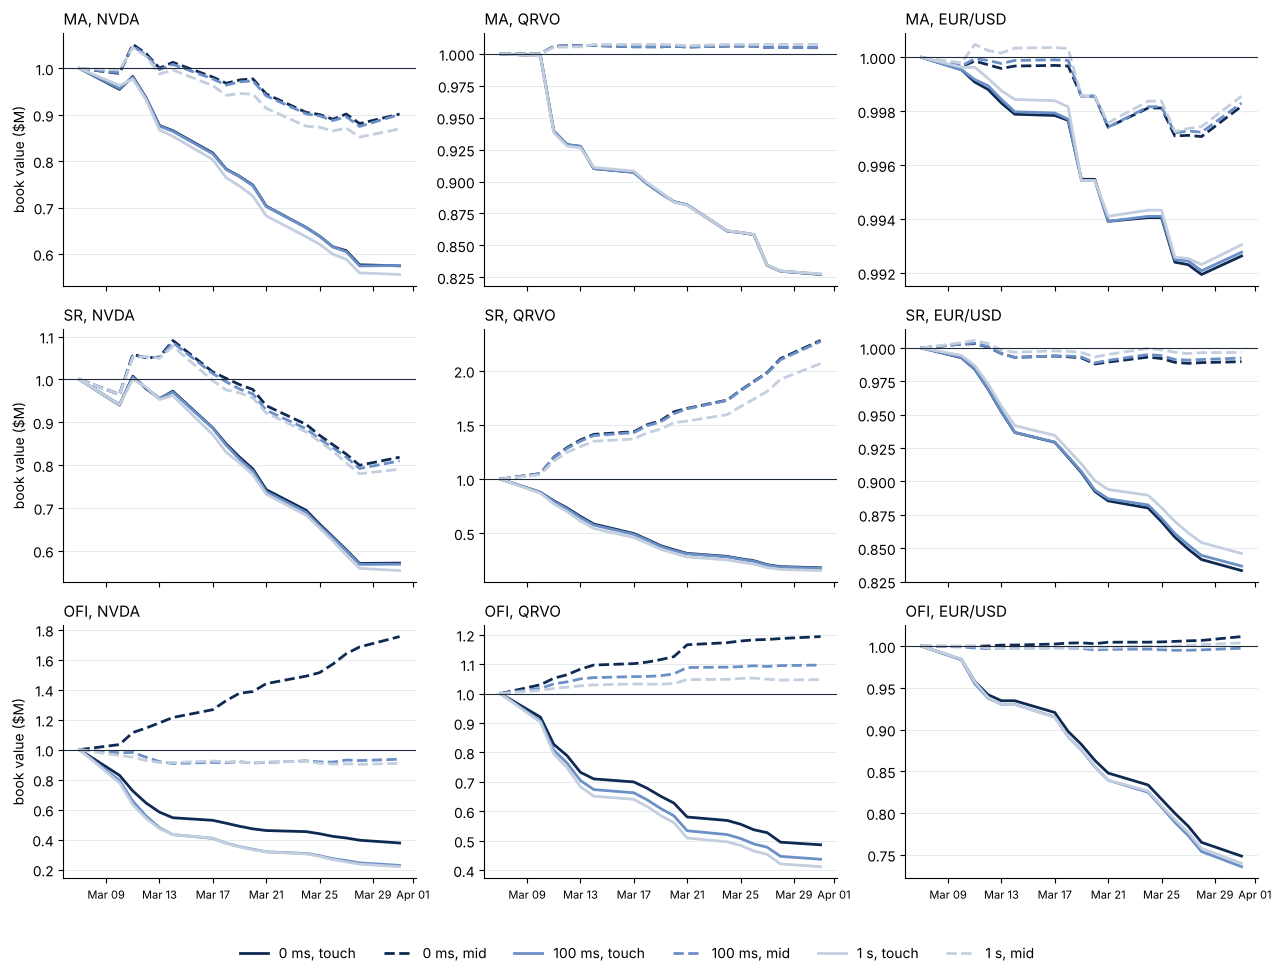

In [ ]:
import matplotlib
import matplotlib.pyplot as plt

TEST_DAYS = pd.bdate_range(pd.Timestamp(CALIB_END) + pd.Timedelta("1D"), "2025-03-31")
DELAYS = list(DELAY)
DELAY_LABEL = {"0ms": "0 ms", "100ms": "100 ms", "1s": "1 s"}
DELAY_COLOR = {"0ms": "#0F2A52", "100ms": "#6B8FC7", "1s": "#C3CEDF"}   # same as the OFI charts

res = pd.read_csv(RES_FILE)
val = pd.read_csv(VAL_FILE, parse_dates=["day"])
signals = [s for s in SIGNALS if s in set(res["signal"])]

def book_path(g):
    """End-of-day book value on every test day (days without a closed trade keep yesterday's value)."""
    return g.set_index("day")["value"].reindex(TEST_DAYS).ffill().fillna(CAPITAL)

paths, daily = {}, []
keys = ["signal", "symbol", "delay", "fill"]
for k, g in val.groupby(keys):
    v = book_path(g)
    paths[k] = v
    r = v / v.shift(1, fill_value=CAPITAL) - 1
    daily.append(pd.DataFrame({**dict(zip(keys, k)), "day": TEST_DAYS, "ret": r.to_numpy()}))
daily = pd.concat(daily, ignore_index=True)

def risk_stats(r, v):
    return pd.Series({
        "mean daily ret (bps)": r.mean() * 1e4,
        "daily vol (bps)": r.std() * 1e4,
        "Sharpe (ann.)": r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan,
        "max drawdown %": ((v / np.maximum.accumulate(np.r_[CAPITAL, v])[1:]) - 1).min() * 100,
        "worst day %": r.min() * 100,
    })

risk = pd.DataFrame({k: risk_stats(g["ret"], paths[k].to_numpy()) for k, g in daily.groupby(keys)}).T
risk.index.names = keys
reports = res.set_index(keys).join(risk)
reports = reports.reindex(pd.MultiIndex.from_product(
    [signals, SYMBOLS, DELAYS, ["touch", "mid"]], names=keys)).dropna(how="all")
reports.to_csv("pnl_reports.csv")

COLS = ["final_value", "total_ret_pct", "round_trips", "hit_rate_pct", "avg_hold_s",
        "mean daily ret (bps)", "Sharpe (ann.)", "max drawdown %"]
for fill, title in [("touch", "buy at ask, sell at bid"), ("mid", "filled at the mid, before the spread")]:
    print(f"\nP&L reports on $1,000,000, Mar 10-31 2025, {title}")
    print(reports.xs(fill, level="fill")[COLS].round(2).to_string())

# equity curves: one panel per signal x asset, one line per delay (solid = touch, dashed = mid)
fig, axes = plt.subplots(len(signals), len(SYMBOLS), figsize=(13, 3.2 * len(signals)),
                         sharex=True, squeeze=False)
for i, sig in enumerate(signals):
    for j, sym in enumerate(SYMBOLS):
        ax = axes[i, j]
        for dl in DELAYS:
            for fill, ls in [("touch", "-"), ("mid", "--")]:
                if (sig, sym, dl, fill) in paths:
                    v = paths[sig, sym, dl, fill]
                    # start at $1M on the last calibration day (plain datetimes work on every matplotlib)
                    t = [pd.Timestamp(CALIB_END).to_pydatetime()] + [pd.Timestamp(d).to_pydatetime() for d in v.index]
                    ax.plot(t, np.r_[CAPITAL, v.to_numpy()] / 1e6, ls, color=DELAY_COLOR[dl], lw=2,
                            label=f"{DELAY_LABEL[dl]}, {fill}" if (i, j) == (0, 0) else None)
        ax.axhline(1, color="#1F2937", lw=0.8)
        ax.set_title(f"{sig}, {sym if sym != 'EURUSD' else 'EUR/USD'}", fontsize=11, loc="left")
        ax.grid(axis="y", color="#E2E6EC", lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        if j == 0:
            ax.set_ylabel("book value ($M)")
        ax.tick_params(axis="x", labelsize=8)
        ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %d"))
fig.legend(frameon=False, ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("pnl_equity_curves.png", dpi=200, bbox_inches="tight")
plt.show()


# Cost of delay (Figure 6)

Figure 6 in the paper plots the day-by-day percentage change in strategy performance when execution is delayed, relative to instantaneous execution, with a Wilcoxon signed-rank test for each delay. Our version does the same comparison per signal and asset:

$$\text{cost of delay}_d = \frac{1}{N}\sum_{i=1}^{N} \left(r_{i,d} - r_{i,0}\right)$$

Here $r_{i,d}$ is the return on the book on test day $i$ with delay $d$, in bps. Negative values mean the delay costs money. Significance comes from a two-sided Wilcoxon signed-rank test of $r_{i,d}$ against $r_{i,0}$ over the $N = 16$ days. The table also reports the change in total return over the month, in percentage points.

We use a difference in returns rather than the paper's relative change because our returns at 0 ms are often negative after the spread. A relative change would then flip sign and lose its meaning. Since every run starts from the same $1M, a difference in bps of the book is directly comparable across assets.

Saved to `cost_of_delay.csv`, `fig6_cost_of_delay.png` (touch) and `fig6_cost_of_delay_mid.png` (mid).

Cost of delay vs. 0 ms (negative = delay hurts); Wilcoxon signed-rank test over 16 days
                           change in daily ret (bps)  days worse than 0 ms  wilcoxon p  change in total ret (pp)
signal symbol fill  delay                                                                                       
MA     NVDA   touch 100ms                      0.707                     9       1.000                     0.077
                    1s                       -20.448                    10       0.105                    -1.865
              mid   100ms                     -0.840                     8       1.000                    -0.098
                    1s                       -23.022                    10       0.093                    -3.205
       QRVO   touch 100ms                      0.176                     0       0.317                     0.023
                    1s                         0.307                     6       0.837                     0.039
        

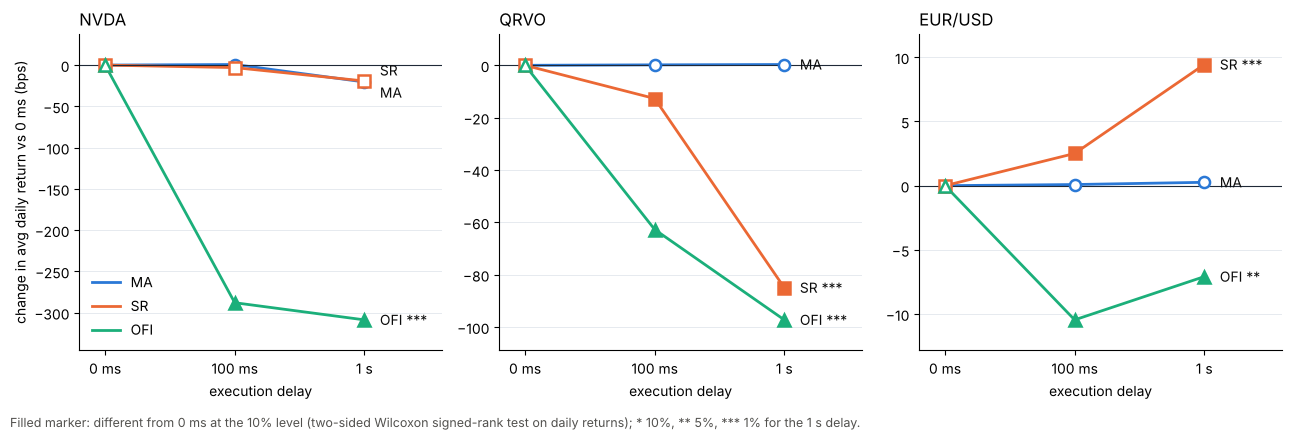

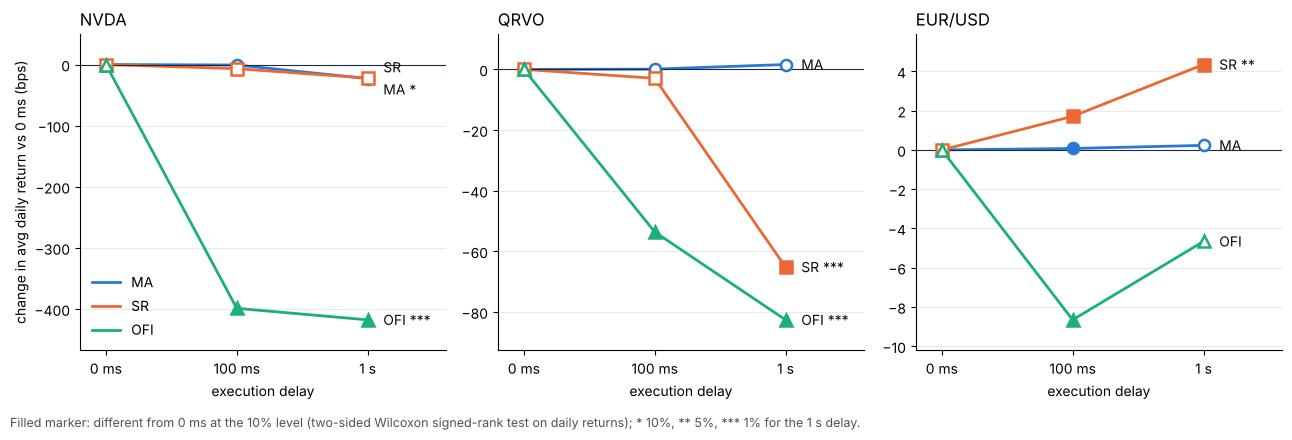

In [ ]:
from scipy.stats import wilcoxon

SIG_COLOR = {"MA": "#2a78d6", "SR": "#eb6834", "OFI": "#1baf7a", "SR-30s": "#eda100"}
SIG_MARK = {"MA": "o", "SR": "s", "OFI": "^", "SR-30s": "D"}

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

# cost of delay per signal / asset / fill: day-by-day change in return vs. 0 ms, as in the paper
wide = daily[daily["signal"].isin(signals)].pivot_table(index=["signal", "symbol", "fill", "day"], columns="delay", values="ret")
rows = []
for (sig, sym, fill), g in wide.groupby(level=["signal", "symbol", "fill"]):
    tot = reports["total_ret_pct"].sort_index().xs((sig, sym, fill), level=["signal", "symbol", "fill"])
    for dl in ["100ms", "1s"]:
        diff = (g[dl] - g["0ms"]).to_numpy()
        p = wilcoxon(g[dl], g["0ms"]).pvalue if np.any(diff != 0) else np.nan
        rows.append({"signal": sig, "symbol": sym, "fill": fill, "delay": dl,
                     "change in daily ret (bps)": diff.mean() * 1e4,
                     "days worse than 0 ms": int((diff < 0).sum()),
                     "wilcoxon p": p,
                     "change in total ret (pp)": tot[dl] - tot["0ms"]})
cod = pd.DataFrame(rows).set_index(["signal", "symbol", "fill", "delay"])
cod = cod.reindex(pd.MultiIndex.from_product(
    [signals, SYMBOLS, ["touch", "mid"], ["100ms", "1s"]], names=cod.index.names)).dropna(how="all")
cod.to_csv("cost_of_delay.csv")
print("Cost of delay vs. 0 ms (negative = delay hurts); Wilcoxon signed-rank test over",
      len(TEST_DAYS), "days")
print(cod.round(3).to_string())

def figure6(fill, fname):
    """Figure 6 analogue: change in average daily return vs. instantaneous execution, by delay."""
    x = np.arange(3)
    cs = cod.sort_index()
    fig, axes = plt.subplots(1, len(SYMBOLS), figsize=(13, 4.2))
    for ax, sym in zip(axes, SYMBOLS):
        ends = []   # (y at 1 s, label) for the direct labels, spaced out below so they never overlap
        for sig in signals:
            if (sig, sym, fill, "100ms") not in cs.index:
                continue
            c = cs.loc[(sig, sym, fill)]
            y = np.r_[0, c.loc[["100ms", "1s"], "change in daily ret (bps)"]]
            p = np.r_[np.nan, c.loc[["100ms", "1s"], "wilcoxon p"]]
            ax.plot(x, y, color=SIG_COLOR[sig], lw=2, label=sig, zorder=2)
            # filled marker = significantly different from 0 ms at 10% (Wilcoxon), hollow = not
            sig_pt = np.r_[False, p[1:] < 0.10]
            for xi, yi, filled in zip(x, y, sig_pt):
                ax.plot(xi, yi, marker=SIG_MARK[sig], ms=8, zorder=3, mew=1.8, mec=SIG_COLOR[sig],
                        mfc=SIG_COLOR[sig] if filled else "white")
            ends.append([y[-1], f"{sig} {stars(p[-1])}".strip()])
        ax.axhline(0, color="#1F2937", lw=0.8)
        ax.set_xticks(x, ["0 ms", "100 ms", "1 s"])
        ax.set_xlim(-0.2, 2.6)
        ax.margins(y=0.12)
        lo, hi = ax.get_ylim()
        gap = (hi - lo) * 0.07
        ends.sort()
        groups = []   # labels closer than `gap` form a group, spread evenly around the group's centre
        for e in ends:
            if groups and e[0] - groups[-1][-1][0] < gap:
                groups[-1].append(e)
            else:
                groups.append([e])
        for grp in groups:
            centre = np.mean([e[0] for e in grp])
            for j, e in enumerate(grp):
                e[0] = centre + (j - (len(grp) - 1) / 2) * gap
        for yl, txt in ends:
            ax.text(x[-1] + 0.12, yl, txt, va="center", fontsize=10, color="#0b0b0b")
        ax.set_title(sym if sym != "EURUSD" else "EUR/USD", fontsize=12, loc="left")
        ax.grid(axis="y", color="#E2E6EC", lw=0.6)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel("execution delay")
    axes[0].set_ylabel("change in avg daily return vs 0 ms (bps)")
    axes[0].legend(frameon=False, loc="lower left")
    fig.text(0.01, -0.03, "Filled marker: different from 0 ms at the 10% level (two-sided Wilcoxon signed-rank "
             "test on daily returns); * 10%, ** 5%, *** 1% for the 1 s delay.", fontsize=9, color="#52514e")
    fig.tight_layout()
    fig.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()

figure6("touch", "fig6_cost_of_delay.png")
figure6("mid", "fig6_cost_of_delay_mid.png")
